In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

# Localizar o CSV
candidates = [
    Path("metrics.csv"),
    Path("results/part1/stageA/metrics.csv"),
    Path("code/results/part1/stageA/metrics.csv"),
]

CSV_PATH = next((p for p in candidates if p.is_file()), None)

if CSV_PATH is None:
    raise FileNotFoundError("Não foi possível localizar metrics.csv")

CSV_PATH = CSV_PATH.resolve()

df = pd.read_csv(CSV_PATH)

# Pasta para resultados do notebook
OUT = CSV_PATH.parent / "report_assets"
OUT.mkdir(exist_ok=True)

print(f"CSV: {CSV_PATH}")
print(f"Registos: {len(df)}")
print(f"Seeds: {sorted(df.seed.unique())}")
print(f"K: {sorted(df.k.unique())}")
print(f"Layouts: {sorted(df.layout.unique())}")
print(f"Splits: {sorted(df.split.unique())}")

display(df.head())

CSV: C:\IAVC\IAVC_proj_2\code\results\part1\stageA\metrics.csv
Registos: 60
Seeds: [42]
K: [32, 64, 128, 256, 512, 1024]
Layouts: ['flat_2x2', 'normal', 'pyramid_L0', 'pyramid_L1', 'pyramid_L2']
Splits: ['train', 'val']


,k,seed,layout,split,images,representation_dimension,spatial_cells,visual_words,sift_dimension,quantization_mean_squared_l2,...,feature_disk_bytes,storage_status,vocabulary_stability_status,vocabulary_stability_score,intra_mean_cosine_distance,inter_mean_cosine_distance,intra_pairs,inter_pairs,inter_minus_intra,zero_vector_pairs_excluded
0,32,42,normal,train,1978,32,1,32,128,88216.471811,...,0,features_in_RAM_only,not_evaluated_single_seed,NaN,0.370917,0.398047,1815,3185,0.027130,0
1,32,42,normal,val,494,32,1,32,128,87652.313201,...,0,features_in_RAM_only,not_evaluated_single_seed,NaN,0.371328,0.400852,1877,3123,0.029524,0
2,32,42,flat_2x2,train,1978,128,4,32,128,88216.471811,...,0,features_in_RAM_only,not_evaluated_single_seed,NaN,0.528532,0.549502,1815,3185,0.020970,0
3,32,42,flat_2x2,val,494,128,4,32,128,87652.313201,...,0,features_in_RAM_only,not_evaluated_single_seed,NaN,0.526082,0.550343,1877,3123,0.024261,0
4,32,42,pyramid_L0,train,1978,32,1,32,128,88216.471811,...,0,features_in_RAM_only,not_evaluated_single_seed,NaN,0.370917,0.398047,1815,3185,0.027130,0


In [2]:
# BoVW global — validação
global_val = (
    df[
        (df["layout"] == "normal") &
        (df["split"] == "val")
    ]
    .sort_values("k")
    .copy()
)

table_k = pd.DataFrame({
    "K": global_val["k"].values,

    "Quant. Error": global_val[
        "quantization_mean_squared_l2"
    ].values,

    "Effective Words": global_val[
        "effective_visual_words"
    ].values,

    "K-means (s)": global_val[
        "kmeans_fit_seconds"
    ].values,

    "Assignment (s)": global_val[
        "assignment_seconds_shared"
    ].values,

    "Storage (KiB/img)": (
        global_val["feature_dense_uint32_bytes"]
        / global_val["images"]
        / 1024
    ).values,
})

display(
    table_k.style
    .format({
        "Quant. Error": "{:,.0f}",
        "Effective Words": "{:.1f}",
        "K-means (s)": "{:.1f}",
        "Assignment (s)": "{:.1f}",
        "Storage (KiB/img)": "{:.2f}",
    })
    .hide(axis="index")
)

table_k.to_csv(OUT / "table_vocabulary.csv", index=False)

K,Quant. Error,Effective Words,K-means (s),Assignment (s),Storage (KiB/img)
32,"87,652",26.9,44.6,20.1,0.12
64,"80,745",48.2,79.0,21.9,0.25
128,"74,394",88.0,123.2,34.9,0.50
256,"68,972",159.2,219.4,55.6,1.00
512,"64,392",287.3,308.6,91.8,2.00
1024,"60,399",516.1,459.6,179.9,4.00


In [4]:
K_SPATIAL = 256

layouts = [
    "normal",
    "flat_2x2",
    "pyramid_L1",
    "pyramid_L2",
]

labels = {
    "normal": "Global",
    "flat_2x2": "2x2",
    "pyramid_L1": "Pyramid L1",
    "pyramid_L2": "Pyramid L2",
}

spatial = (
    df[
        (df["k"] == K_SPATIAL) &
        (df["split"] == "val") &
        (df["layout"].isin(layouts))
    ]
    .copy()
)

spatial["layout"] = pd.Categorical(
    spatial["layout"],
    categories=layouts,
    ordered=True
)

spatial = spatial.sort_values("layout")

table_spatial = pd.DataFrame({
    "Layout": spatial["layout"].map(labels).values,

    "Dimension": spatial[
        "representation_dimension"
    ].values,

    "Sparsity (%)": (
        spatial["histogram_sparsity"] * 100
    ).values,

    "Inter - Intra": spatial[
        "inter_minus_intra"
    ].values,

    "Storage (KiB/img)": (
        spatial["feature_dense_uint32_bytes"]
        / spatial["images"]
        / 1024
    ).values,
})

display(
    table_spatial.style
    .format({
        "Sparsity (%)": "{:.2f}",
        "Inter - Intra": "{:.4f}",
        "Storage (KiB/img)": "{:.1f}",
    })
    .hide(axis="index")
)

table_spatial.to_csv(
    OUT / "table_spatial.csv",
    index=False
)

Layout,Dimension,Sparsity (%),Inter - Intra,Storage (KiB/img)
Global,256,3.83,0.0191,1.0
2x2,1024,20.39,0.0141,4.0
Pyramid L1,1280,17.08,0.0178,5.0
Pyramid L2,5376,44.42,0.0128,21.0


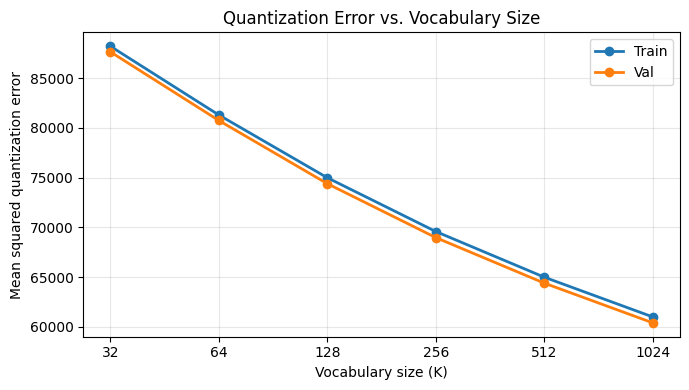

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))

for split in ["train", "val"]:

    data = (
        df[
            (df["layout"] == "normal") &
            (df["split"] == split)
        ]
        .sort_values("k")
    )

    ax.plot(
        data["k"],
        data["quantization_mean_squared_l2"],
        marker="o",
        linewidth=2,
        label=split.capitalize()
    )

ax.set_xscale("log", base=2)

ax.set_xticks(sorted(df["k"].unique()))
ax.set_xticklabels(sorted(df["k"].unique()))

ax.set_xlabel("Vocabulary size (K)")
ax.set_ylabel("Mean squared quantization error")
ax.set_title("Quantization Error vs. Vocabulary Size")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    OUT / "quantization_vs_k.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

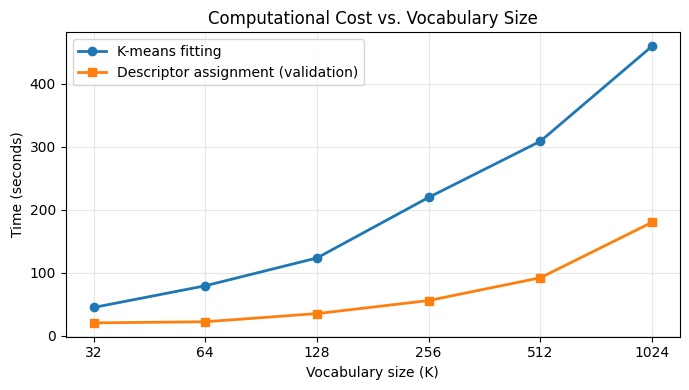

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    global_val["k"],
    global_val["kmeans_fit_seconds"],
    marker="o",
    linewidth=2,
    label="K-means fitting"
)

ax.plot(
    global_val["k"],
    global_val["assignment_seconds_shared"],
    marker="s",
    linewidth=2,
    label="Descriptor assignment (validation)"
)

ax.set_xscale("log", base=2)

ax.set_xticks(global_val["k"])
ax.set_xticklabels(global_val["k"])

ax.set_xlabel("Vocabulary size (K)")
ax.set_ylabel("Time (seconds)")
ax.set_title("Computational Cost vs. Vocabulary Size")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    OUT / "computation_vs_k.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

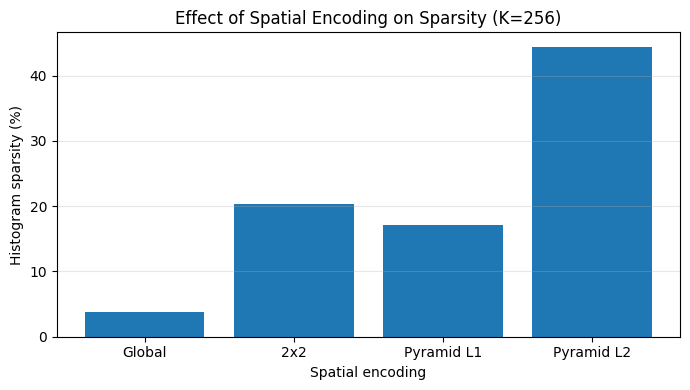

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    table_spatial["Layout"],
    table_spatial["Sparsity (%)"]
)

ax.set_xlabel("Spatial encoding")
ax.set_ylabel("Histogram sparsity (%)")

ax.set_title(
    f"Effect of Spatial Encoding on Sparsity (K={K_SPATIAL})"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    OUT / "spatial_sparsity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
AP_PATH = CSV_PATH.parent / "svm_ap.csv"

if AP_PATH.exists():

    ap_df = pd.read_csv(AP_PATH)

    print("Dimensão:", ap_df.shape)
    print("\nColunas:")
    print(ap_df.columns.tolist())

    display(ap_df.head(10))

else:
    print("svm_ap.csv não encontrado.")

Dimensão: (90, 16)

Colunas:
['category', 'k', 'layout', 'seed', 'selected_within_encoding', 'test_ap', 'C', 'normalization', 'max_iter', 'tol', 'train_ap', 'validation_ap', 'fit_seconds', 'validation_inference_seconds', 'train_images', 'validation_images']


,category,k,layout,seed,selected_within_encoding,test_ap,C,normalization,max_iter,tol,train_ap,validation_ap,fit_seconds,validation_inference_seconds,train_images,validation_images
0,motorbike,32,normal,42,False,NaN,0.1,l2,20000,0.0001,0.347516,0.273774,0.029723,0.000033,911,228
1,motorbike,32,normal,42,False,NaN,1.0,l2,20000,0.0001,0.430477,0.349058,0.006669,0.000019,911,228
2,motorbike,32,normal,42,True,NaN,10.0,l2,20000,0.0001,0.451410,0.351680,0.007338,0.000024,911,228
3,motorbike,32,flat_2x2,42,False,NaN,0.1,l2,20000,0.0001,0.568041,0.305391,0.014798,0.000165,911,228
4,motorbike,32,flat_2x2,42,False,NaN,1.0,l2,20000,0.0001,0.678531,0.430657,0.034270,0.000184,911,228
5,motorbike,32,flat_2x2,42,True,NaN,10.0,l2,20000,0.0001,0.675585,0.433076,0.066819,0.000220,911,228
6,motorbike,32,pyramid_L0,42,False,NaN,0.1,l2,20000,0.0001,0.347516,0.273774,0.005285,0.000021,911,228
7,motorbike,32,pyramid_L0,42,False,NaN,1.0,l2,20000,0.0001,0.430477,0.349058,0.006519,0.000014,911,228
8,motorbike,32,pyramid_L0,42,True,NaN,10.0,l2,20000,0.0001,0.451410,0.351680,0.007102,0.000017,911,228
9,motorbike,32,pyramid_L1,42,False,NaN,0.1,l2,20000,0.0001,0.567363,0.305195,0.028863,0.000235,911,228
